In [1]:
import os
import re
import random
import shutil
import hashlib
import warnings
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers

from PIL import Image, ImageFile, ImageOps, ImageEnhance

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

warnings.filterwarnings("ignore")

ImageFile.LOAD_TRUNCATED_IMAGES = True

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow Version:", tf.__version__)
print("Libraries imported successfully.")

TensorFlow Version: 2.21.0
Libraries imported successfully.


In [2]:
gpus = tf.config.list_physical_devices("GPU")

if gpus:
    print("GPU Available:", gpus)

    for gpu in gpus:
        try:
            tf.config.experimental.set_memory_growth(gpu, True)
        except RuntimeError:
            pass
else:
    print("GPU not found. Training will use CPU.")
    print("For faster training, select Runtime > Change runtime type > T4 GPU.")

GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
!pip -q install kagglehub

In [3]:
import kagglehub

print("Downloading Tomato Dataset 1...")

tomato_dataset_1 = kagglehub.dataset_download(
    "cookiefinder/tomato-disease-multiple-sources"
)

print("Tomato Dataset 1:", tomato_dataset_1)


print("\nDownloading PlantVillage Dataset...")

plantdisease_dataset = kagglehub.dataset_download(
    "emmarex/plantdisease"
)

print("PlantVillage Dataset:", plantdisease_dataset)


print("\nDownloading Potato Dataset...")

potato_dataset_2 = kagglehub.dataset_download(
    "nirmalsankalana/potato-leaf-disease-dataset"
)

print("Potato Dataset 2:", potato_dataset_2)


print("\nAll dataset downloads completed.")

100%|██████████| 1.37G/1.37G [00:15<00:00, 93.3MB/s]

Extracting files...


Tomato Dataset 1: /root/.cache/kagglehub/datasets/cookiefinder/tomato-disease-multiple-sources/versions/1

Using Colab cache for faster access to the 'plantdisease' dataset.
PlantVillage Dataset: /kaggle/input/plantdisease



100%|██████████| 718M/718M [00:09<00:00, 78.0MB/s]

Extracting files...


Potato Dataset 2: /root/.cache/kagglehub/datasets/nirmalsankalana/potato-leaf-disease-dataset/versions/1

All dataset downloads completed.


In [4]:
CLASS_NAMES = [
    "Tomato_Early_Blight",
    "Tomato_Late_Blight",
    "Tomato_Mosaic_Virus",
    "Tomato_Healthy",
    "Potato_Early_Blight",
    "Potato_Late_Blight",
    "Potato_Healthy"
]

NUM_CLASSES = len(CLASS_NAMES)

TARGET_IMAGES_PER_CLASS = 1500

IMAGE_HEIGHT = 300
IMAGE_WIDTH = 300
CHANNELS = 3

BATCH_SIZE = 32

print("Number of Classes:", NUM_CLASSES)
print("Target Training Images Per Class:", TARGET_IMAGES_PER_CLASS)
print("Total Target Training Images:", NUM_CLASSES * TARGET_IMAGES_PER_CLASS)

for class_name in CLASS_NAMES:
    print(class_name)

Number of Classes: 7
Target Training Images Per Class: 1500
Total Target Training Images: 10500
Tomato_Early_Blight
Tomato_Late_Blight
Tomato_Mosaic_Virus
Tomato_Healthy
Potato_Early_Blight
Potato_Late_Blight
Potato_Healthy


In [5]:
BASE_DIR = "/content/Tomato_Potato_Disease_Dataset"

TRAIN_DIR = os.path.join(BASE_DIR, "train")
VAL_DIR = os.path.join(BASE_DIR, "validation")

if os.path.exists(BASE_DIR):
    shutil.rmtree(BASE_DIR)

os.makedirs(TRAIN_DIR)
os.makedirs(VAL_DIR)

for class_name in CLASS_NAMES:
    os.makedirs(os.path.join(TRAIN_DIR, class_name))
    os.makedirs(os.path.join(VAL_DIR, class_name))

print("Dataset directories created successfully.")
print("Training Directory:", TRAIN_DIR)
print("Validation Directory:", VAL_DIR)

Dataset directories created successfully.
Training Directory: /content/Tomato_Potato_Disease_Dataset/train
Validation Directory: /content/Tomato_Potato_Disease_Dataset/validation


In [6]:
DATASET_ROOTS = {
    "tomato_dataset_1": tomato_dataset_1,
    "plantdisease_dataset": plantdisease_dataset,
    "potato_dataset_2": potato_dataset_2
}

for dataset_name, root_path in DATASET_ROOTS.items():

    print("\n" + "=" * 70)
    print("DATASET:", dataset_name)
    print("ROOT:", root_path)
    print("=" * 70)

    folder_count = 0

    for root, dirs, files in os.walk(root_path):

        dirs[:] = [
            d for d in dirs
            if d not in {".git", "__pycache__"}
        ]

        image_count = sum(
            1 for f in files
            if f.lower().endswith(
                (".jpg", ".jpeg", ".png", ".bmp", ".webp")
            )
        )

        if image_count > 0:
            print(
                os.path.relpath(root, root_path),
                "| Images:", image_count
            )

            folder_count += 1

            if folder_count >= 60:
                print("More folders may exist; listing truncated.")
                break



DATASET: tomato_dataset_1
ROOT: /root/.cache/kagglehub/datasets/cookiefinder/tomato-disease-multiple-sources/versions/1
train/Early_blight | Images: 2455
train/healthy | Images: 3051
train/Leaf_Mold | Images: 2754
train/powdery_mildew | Images: 1004
train/Tomato_mosaic_virus | Images: 2153
train/Bacterial_spot | Images: 2826
train/Spider_mites Two-spotted_spider_mite | Images: 1747
train/Target_Spot | Images: 1827
train/Septoria_leaf_spot | Images: 2882
train/Tomato_Yellow_Leaf_Curl_Virus | Images: 2039
train/Late_blight | Images: 3113
valid/Early_blight | Images: 643
valid/healthy | Images: 806
valid/Leaf_Mold | Images: 739
valid/powdery_mildew | Images: 252
valid/Tomato_mosaic_virus | Images: 584
valid/Bacterial_spot | Images: 732
valid/Spider_mites Two-spotted_spider_mite | Images: 435
valid/Target_Spot | Images: 457
valid/Septoria_leaf_spot | Images: 746
valid/Tomato_Yellow_Leaf_Curl_Virus | Images: 498
valid/Late_blight | Images: 792

DATASET: plantdisease_dataset
ROOT: /kaggle/i

In [7]:
def normalize_name(text):

    text = text.lower()
    text = text.replace("_", " ")
    text = text.replace("-", " ")
    text = text.replace(".", " ")

    return re.sub(r"\s+", " ", text).strip()


def identify_class(path, dataset_name):

    normalized_path = normalize_name(path)

    parts = normalized_path.split("/")

    # Find the crop name from the path.
    crop = None

    for part in parts:

        if "tomato" in part:
            crop = "Tomato"

        elif "potato" in part:
            crop = "Potato"

    if crop is None:
        return None

    # Tomato classes
    if crop == "Tomato":

        if (
            "mosaic" in normalized_path
            or "tomato yellow leaf curl virus" in normalized_path
        ):

            # Only accept explicit mosaic-virus matches.
            if "mosaic" in normalized_path:
                return "Tomato_Mosaic_Virus"

        if "early blight" in normalized_path:
            return "Tomato_Early_Blight"

        if "late blight" in normalized_path:
            return "Tomato_Late_Blight"

        if (
            "healthy" in normalized_path
            or "healthy tomato" in normalized_path
        ):
            return "Tomato_Healthy"

    # Potato classes
    elif crop == "Potato":

        if "early blight" in normalized_path:
            return "Potato_Early_Blight"

        if "late blight" in normalized_path:
            return "Potato_Late_Blight"

        if "healthy" in normalized_path:
            return "Potato_Healthy"

    return None

In [8]:
IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
}

class_images = defaultdict(list)

for dataset_name, root_path in DATASET_ROOTS.items():

    print("\nScanning:", dataset_name)

    for root, dirs, files in os.walk(root_path):

        dirs[:] = [
            d for d in dirs
            if d not in {".git", "__pycache__"}
        ]

        for filename in files:

            extension = Path(filename).suffix.lower()

            if extension not in IMAGE_EXTENSIONS:
                continue

            image_path = os.path.join(root, filename)

            relative_path = os.path.relpath(
                image_path,
                root_path
            )

            detected_class = identify_class(
                relative_path,
                dataset_name
            )

            if detected_class is None:
                continue

            class_images[detected_class].append(image_path)

print("\n" + "=" * 70)
print("RAW IMAGE COUNTS")
print("=" * 70)

for class_name in CLASS_NAMES:

    count = len(set(class_images[class_name]))

    print(f"{class_name:28} : {count}")


Scanning: tomato_dataset_1

Scanning: plantdisease_dataset

Scanning: potato_dataset_2

RAW IMAGE COUNTS
Tomato_Early_Blight          : 2117
Tomato_Late_Blight           : 3945
Tomato_Mosaic_Virus          : 3486
Tomato_Healthy               : 3259
Potato_Early_Blight          : 2005
Potato_Late_Blight           : 2003
Potato_Healthy               : 304


In [9]:
def calculate_file_hash(file_path):

    hasher = hashlib.sha256()

    with open(file_path, "rb") as file:

        for chunk in iter(
            lambda: file.read(1024 * 1024),
            b""
        ):
            hasher.update(chunk)

    return hasher.hexdigest()


unique_class_images = defaultdict(list)

for class_name in CLASS_NAMES:

    seen_hashes = set()

    for image_path in class_images[class_name]:

        try:

            file_hash = calculate_file_hash(image_path)

            if file_hash not in seen_hashes:

                seen_hashes.add(file_hash)

                unique_class_images[class_name].append(
                    image_path
                )

        except Exception:
            continue


class_images = unique_class_images

print("Image counts after duplicate removal:")

for class_name in CLASS_NAMES:

    print(
        f"{class_name:28} : "
        f"{len(class_images[class_name])}"
    )

Image counts after duplicate removal:
Tomato_Early_Blight          : 1117
Tomato_Late_Blight           : 2028
Tomato_Mosaic_Virus          : 2739
Tomato_Healthy               : 1662
Potato_Early_Blight          : 1005
Potato_Late_Blight           : 1003
Potato_Healthy               : 152


In [10]:
train_originals = {}
val_originals = {}

for class_name in CLASS_NAMES:

    paths = list(class_images[class_name])

    random.Random(SEED).shuffle(paths)

    if len(paths) < 2:

        raise ValueError(
            f"{class_name} has fewer than 2 usable images. "
            "Check dataset paths and class mapping before continuing."
        )

    train_paths, val_paths = train_test_split(
        paths,
        test_size=0.20,
        random_state=SEED
    )

    train_originals[class_name] = train_paths
    val_originals[class_name] = val_paths

print("Original images split into training and validation.")

print("\nOriginal training image counts:")

for class_name in CLASS_NAMES:

    print(
        class_name,
        ":",
        len(train_originals[class_name])
    )

print("\nOriginal validation image counts:")

for class_name in CLASS_NAMES:

    print(
        class_name,
        ":",
        len(val_originals[class_name])
    )

Original images split into training and validation.

Original training image counts:
Tomato_Early_Blight : 893
Tomato_Late_Blight : 1622
Tomato_Mosaic_Virus : 2191
Tomato_Healthy : 1329
Potato_Early_Blight : 804
Potato_Late_Blight : 802
Potato_Healthy : 121

Original validation image counts:
Tomato_Early_Blight : 224
Tomato_Late_Blight : 406
Tomato_Mosaic_Virus : 548
Tomato_Healthy : 333
Potato_Early_Blight : 201
Potato_Late_Blight : 201
Potato_Healthy : 31


In [11]:
def copy_original_images(image_paths, destination_folder):

    copied = 0

    for index, source_path in enumerate(image_paths):

        try:

            with Image.open(source_path) as img:

                img = img.convert("RGB")

                destination_path = os.path.join(
                    destination_folder,
                    f"original_{index:06d}.jpg"
                )

                img.save(
                    destination_path,
                    "JPEG",
                    quality=95
                )

                copied += 1

        except Exception as error:

            print(
                "Skipping unreadable image:",
                source_path,
                str(error)[:100]
            )

    return copied


for class_name in CLASS_NAMES:

    destination = os.path.join(
        TRAIN_DIR,
        class_name
    )

    copied = copy_original_images(
        train_originals[class_name],
        destination
    )

    print(class_name, "Original images copied:", copied)

Tomato_Early_Blight Original images copied: 893
Tomato_Late_Blight Original images copied: 1622
Tomato_Mosaic_Virus Original images copied: 2191
Tomato_Healthy Original images copied: 1329
Potato_Early_Blight Original images copied: 804
Potato_Late_Blight Original images copied: 802
Potato_Healthy Original images copied: 121


In [12]:
for class_name in CLASS_NAMES:

    destination = os.path.join(
        VAL_DIR,
        class_name
    )

    copied = copy_original_images(
        val_originals[class_name],
        destination
    )

    print(
        class_name,
        "Validation images copied:",
        copied
    )

print("\nValidation dataset created successfully.")

Tomato_Early_Blight Validation images copied: 224
Tomato_Late_Blight Validation images copied: 406
Tomato_Mosaic_Virus Validation images copied: 548
Tomato_Healthy Validation images copied: 333
Potato_Early_Blight Validation images copied: 201
Potato_Late_Blight Validation images copied: 201
Potato_Healthy Validation images copied: 31

Validation dataset created successfully.


In [13]:
from PIL import ImageEnhance

TARGET_IMAGES_PER_CLASS = 1500

def augment_image(img):

    img = img.convert("RGB")

    # Random horizontal flip
    if random.random() < 0.5:
        img = ImageOps.mirror(img)

    # Random vertical flip
    if random.random() < 0.15:
        img = ImageOps.flip(img)

    # Small rotation
    angle = random.uniform(-18, 18)

    img = img.rotate(
        angle,
        resample=Image.Resampling.BILINEAR,
        fillcolor=(0, 0, 0)
    )

    # Random brightness
    brightness = random.uniform(0.85, 1.15)

    img = ImageEnhance.Brightness(
        img
    ).enhance(brightness)

    # Random contrast
    contrast = random.uniform(0.85, 1.15)

    img = ImageEnhance.Contrast(
        img
    ).enhance(contrast)

    # Random crop and resize
    width, height = img.size

    crop_fraction = random.uniform(0.85, 1.0)

    crop_width = max(
        1,
        int(width * crop_fraction)
    )

    crop_height = max(
        1,
        int(height * crop_fraction)
    )

    left = random.randint(
        0,
        width - crop_width
    )

    top = random.randint(
        0,
        height - crop_height
    )

    img = img.crop(
        (
            left,
            top,
            left + crop_width,
            top + crop_height
        )
    )

    img = img.resize(
        (IMAGE_WIDTH, IMAGE_HEIGHT),
        Image.Resampling.BILINEAR
    )

    return img


for class_name in CLASS_NAMES:

    class_dir = os.path.join(
        TRAIN_DIR,
        class_name
    )

    existing_images = [
        os.path.join(class_dir, filename)
        for filename in os.listdir(class_dir)
        if filename.lower().endswith(
            (".jpg", ".jpeg", ".png", ".bmp", ".webp")
        )
    ]

    current_count = len(existing_images)

    if current_count == 0:

        raise ValueError(
            f"No training images found for {class_name}"
        )

    if current_count >= TARGET_IMAGES_PER_CLASS:

        print(
            class_name,
            "Already has",
            current_count,
            "images. No augmentation required."
        )

        continue

    print(
        f"\nAugmenting {class_name}: "
        f"{current_count} -> {TARGET_IMAGES_PER_CLASS}"
    )

    images_needed = (
        TARGET_IMAGES_PER_CLASS - current_count
    )

    for i in range(images_needed):

        source_path = random.choice(
            existing_images
        )

        try:

            with Image.open(source_path) as source_img:

                augmented_img = augment_image(
                    source_img
                )

            output_path = os.path.join(
                class_dir,
                f"augmented_{i:06d}.jpg"
            )

            augmented_img.save(
                output_path,
                "JPEG",
                quality=95
            )

        except Exception as error:

            print("Augmentation error:", error)

    final_count = len([
        f for f in os.listdir(class_dir)
        if f.lower().endswith(
            (".jpg", ".jpeg", ".png", ".bmp", ".webp")
        )
    ])

    print(
        class_name,
        "Final training images:",
        final_count
    )

print("\nTraining dataset balancing completed.")


Augmenting Tomato_Early_Blight: 893 -> 1500
Tomato_Early_Blight Final training images: 1500
Tomato_Late_Blight Already has 1622 images. No augmentation required.
Tomato_Mosaic_Virus Already has 2191 images. No augmentation required.

Augmenting Tomato_Healthy: 1329 -> 1500
Tomato_Healthy Final training images: 1500

Augmenting Potato_Early_Blight: 804 -> 1500
Potato_Early_Blight Final training images: 1500

Augmenting Potato_Late_Blight: 802 -> 1500
Potato_Late_Blight Final training images: 1500

Augmenting Potato_Healthy: 121 -> 1500
Potato_Healthy Final training images: 1500

Training dataset balancing completed.


In [14]:
train_counts = {}
val_counts = {}

for class_name in CLASS_NAMES:

    train_folder = os.path.join(
        TRAIN_DIR,
        class_name
    )

    val_folder = os.path.join(
        VAL_DIR,
        class_name
    )

    train_count = len([
        f for f in os.listdir(train_folder)
        if f.lower().endswith(
            (".jpg", ".jpeg", ".png", ".bmp", ".webp")
        )
    ])

    val_count = len([
        f for f in os.listdir(val_folder)
        if f.lower().endswith(
            (".jpg", ".jpeg", ".png", ".bmp", ".webp")
        )
    ])

    train_counts[class_name] = train_count
    val_counts[class_name] = val_count


dataset_summary = pd.DataFrame({
    "Class": CLASS_NAMES,
    "Training Images": [
        train_counts[c] for c in CLASS_NAMES
    ],
    "Validation Images": [
        val_counts[c] for c in CLASS_NAMES
    ]
})

display(dataset_summary)

print(
    "\nTotal Training Images:",
    sum(train_counts.values())
)

print(
    "Total Validation Images:",
    sum(val_counts.values())
)

,Class,Training Images,Validation Images
0,Tomato_Early_Blight,1500,224
1,Tomato_Late_Blight,1622,406
2,Tomato_Mosaic_Virus,2191,548
3,Tomato_Healthy,1500,333
4,Potato_Early_Blight,1500,201
5,Potato_Late_Blight,1500,201
6,Potato_Healthy,1500,31



Total Training Images: 11313
Total Validation Images: 1944


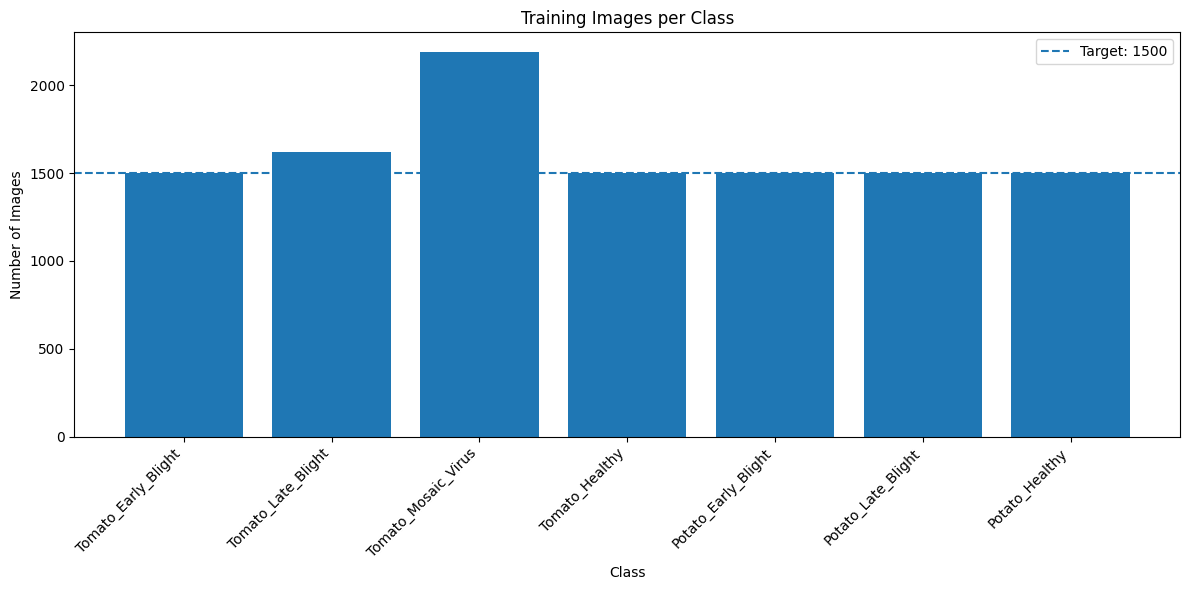

In [15]:
plt.figure(figsize=(12, 6))

plt.bar(
    dataset_summary["Class"],
    dataset_summary["Training Images"]
)

plt.title("Training Images per Class")
plt.xlabel("Class")
plt.ylabel("Number of Images")

plt.xticks(
    rotation=45,
    ha="right"
)

plt.axhline(
    y=TARGET_IMAGES_PER_CLASS,
    linestyle="--",
    label="Target: 1500"
)

plt.legend()
plt.tight_layout()
plt.show()

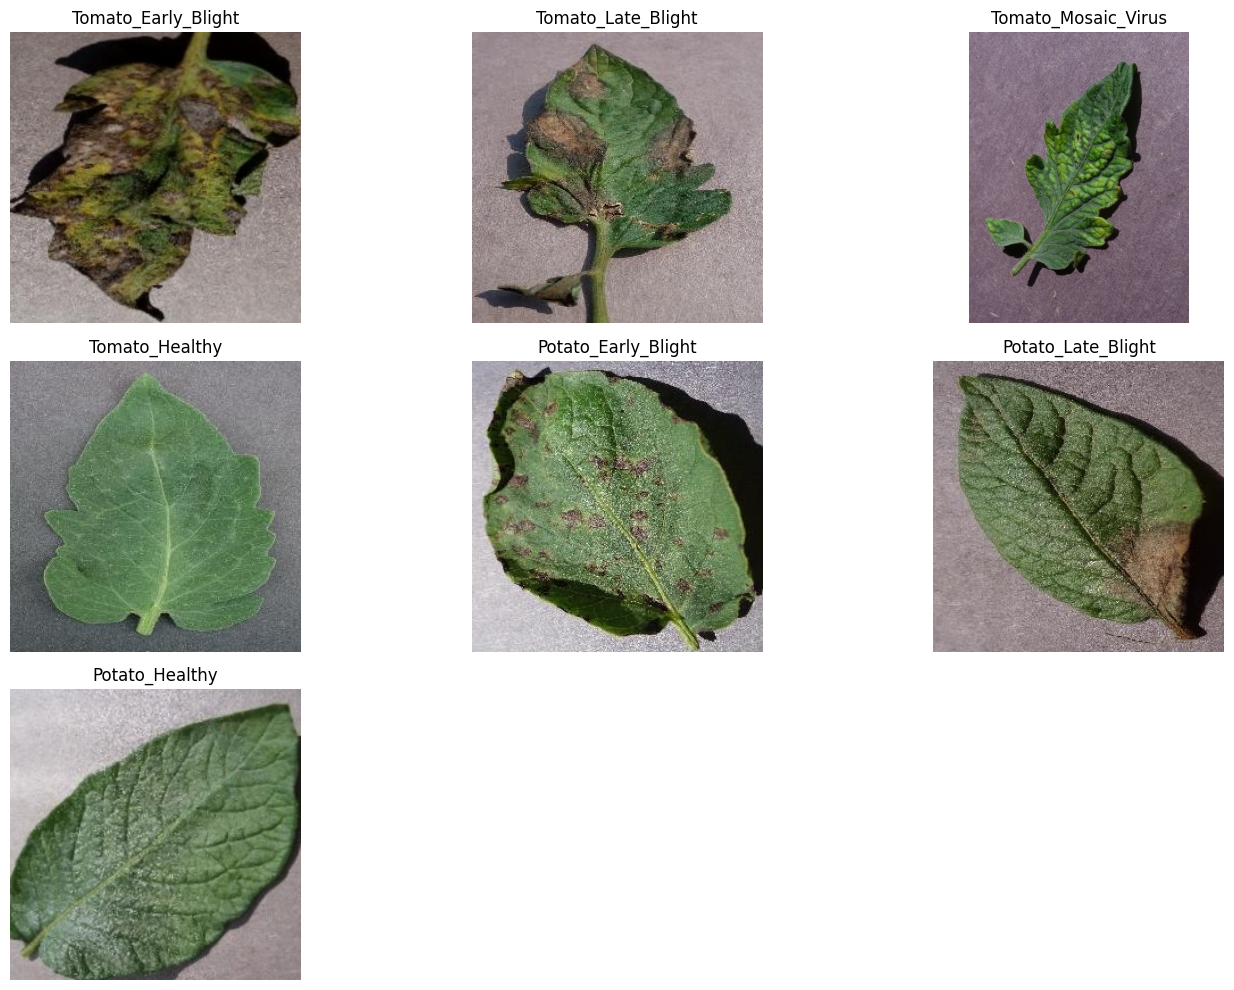

In [16]:
plt.figure(figsize=(14, 10))

for i, class_name in enumerate(CLASS_NAMES):

    class_dir = os.path.join(
        TRAIN_DIR,
        class_name
    )

    image_files = [
        f for f in os.listdir(class_dir)
        if f.lower().endswith(
            (".jpg", ".jpeg", ".png", ".bmp", ".webp")
        )
    ]

    if not image_files:
        continue

    image_path = os.path.join(
        class_dir,
        random.choice(image_files)
    )

    with Image.open(image_path) as img:
        img = img.convert("RGB")

        plt.subplot(3, 3, i + 1)
        plt.imshow(img)
        plt.title(class_name)
        plt.axis("off")

plt.tight_layout()
plt.show()

In [17]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=(IMAGE_HEIGHT, IMAGE_WIDTH),
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=True,
    seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    image_size=(IMAGE_HEIGHT, IMAGE_WIDTH),
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=False
)

class_names = train_ds.class_names

print("\nClass Names:")
print(class_names)

print("\nNumber of Classes:", len(class_names))

Found 11313 files belonging to 7 classes.
Found 1944 files belonging to 7 classes.

Class Names:
['Potato_Early_Blight', 'Potato_Healthy', 'Potato_Late_Blight', 'Tomato_Early_Blight', 'Tomato_Healthy', 'Tomato_Late_Blight', 'Tomato_Mosaic_Virus']

Number of Classes: 7


In [18]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(
    AUTOTUNE
)

val_ds = val_ds.prefetch(
    AUTOTUNE
)

print("Dataset pipeline optimized.")

Dataset pipeline optimized.


In [19]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.08),
    layers.RandomContrast(0.10)
], name="data_augmentation")

print("Training augmentation configured.")

Training augmentation configured.


In [20]:
base_model = tf.keras.applications.EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(
        IMAGE_HEIGHT,
        IMAGE_WIDTH,
        CHANNELS
    )
)

base_model.trainable = False

print("EfficientNetB0 loaded successfully.")
print("Total Backbone Layers:", len(base_model.layers))

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
EfficientNetB0 loaded successfully.
Total Backbone Layers: 238


In [21]:
inputs = keras.Input(
    shape=(
        IMAGE_HEIGHT,
        IMAGE_WIDTH,
        CHANNELS
    )
)

x = data_augmentation(inputs)

x = tf.keras.applications.efficientnet.preprocess_input(x)

x = base_model(
    x,
    training=False
)

x = layers.GlobalAveragePooling2D()(x)

x = layers.BatchNormalization()(x)

x = layers.Dense(
    256,
    activation="relu",
    kernel_regularizer=regularizers.l2(1e-4)
)(x)

x = layers.Dropout(0.35)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

model = keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="Tomato_Potato_Disease_Detection"
)

model.summary()

Model: "Tomato_Potato_Disease_Detection"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 300, 300, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 300, 300, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 10, 10, 1280)   │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │         1,799 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,384,426 (16.73 MB)

 Trainable params: 332,295 (1.27 MB)

 Non-trainable params: 4,052,131 (15.46 MB)

In [22]:
model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=1e-3
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully.")

Model compiled successfully.


In [23]:
callbacks = [

    keras.callbacks.ModelCheckpoint(
        "/content/Best_Tomato_Potato_Model.keras",
        monitor="val_accuracy",
        save_best_only=True,
        mode="max",
        verbose=1
    ),

    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.3,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

print("Training callbacks configured.")

Training callbacks configured.


In [24]:
EPOCHS = 20

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

Epoch 1/20
354/354 ━━━━━━━━━━━━━━━━━━━━ 0s 132ms/step - accuracy: 0.8338 - loss: 0.5653
Epoch 1: val_accuracy improved from None to 0.96245, saving model to /content/Best_Tomato_Potato_Model.keras

Epoch 1: finished saving model to /content/Best_Tomato_Potato_Model.keras
354/354 ━━━━━━━━━━━━━━━━━━━━ 77s 167ms/step - accuracy: 0.9003 - loss: 0.3601 - val_accuracy: 0.9624 - val_loss: 0.1532 - learning_rate: 0.0010
Epoch 2/20
354/354 ━━━━━━━━━━━━━━━━━━━━ 0s 140ms/step - accuracy: 0.9519 - loss: 0.1886
Epoch 2: val_accuracy improved from 0.96245 to 0.96451, saving model to /content/Best_Tomato_Potato_Model.keras

Epoch 2: finished saving model to /content/Best_Tomato_Potato_Model.keras
354/354 ━━━━━━━━━━━━━━━━━━━━ 74s 166ms/step - accuracy: 0.9539 - loss: 0.1869 - val_accuracy: 0.9645 - val_loss: 0.1458 - learning_rate: 0.0010
Epoch 3/20
354/354 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step - accuracy: 0.9593 - loss: 0.1711
Epoch 3: val_accuracy improved from 0.96451 to 0.97479, saving model to /cont

In [25]:
base_model.trainable = True

# Freeze the earlier layers.
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep Batch Normalization layers frozen for stability.
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("Fine-tuning configuration completed.")

Fine-tuning configuration completed.


In [26]:
fine_tune_history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks
)

Epoch 1/10
354/354 ━━━━━━━━━━━━━━━━━━━━ 0s 158ms/step - accuracy: 0.9931 - loss: 0.0754
Epoch 1: val_accuracy did not improve from 0.98663
354/354 ━━━━━━━━━━━━━━━━━━━━ 81s 189ms/step - accuracy: 0.9928 - loss: 0.0760 - val_accuracy: 0.9866 - val_loss: 0.1024 - learning_rate: 1.0000e-05
Epoch 2/10
354/354 ━━━━━━━━━━━━━━━━━━━━ 0s 156ms/step - accuracy: 0.9955 - loss: 0.0718
Epoch 2: val_accuracy improved from 0.98663 to 0.98765, saving model to /content/Best_Tomato_Potato_Model.keras

Epoch 2: finished saving model to /content/Best_Tomato_Potato_Model.keras
354/354 ━━━━━━━━━━━━━━━━━━━━ 67s 188ms/step - accuracy: 0.9948 - loss: 0.0713 - val_accuracy: 0.9877 - val_loss: 0.1008 - learning_rate: 1.0000e-05
Epoch 3/10
354/354 ━━━━━━━━━━━━━━━━━━━━ 0s 156ms/step - accuracy: 0.9942 - loss: 0.0718
Epoch 3: val_accuracy improved from 0.98765 to 0.98817, saving model to /content/Best_Tomato_Potato_Model.keras

Epoch 3: finished saving model to /content/Best_Tomato_Potato_Model.keras
354/354 ━━━━━━━

In [27]:
import os
import tensorflow as tf

candidate_paths = [
    '/content/Best_Tomato_Potato_Model.keras',
    'Model/Tomato_Potato_Disease_Model.keras',
    'Tomato_Potato_Disease_Model.keras'
]
for p in candidate_paths:
    if os.path.exists(p):
        best_model = tf.keras.models.load_model(p)
        print(f'Best model loaded from: {p}')
        break

print('Best model loaded successfully.')
print('Output shape:', best_model.output_shape)


Best model loaded from: Model/Tomato_Potato_Disease_Model.keras
Best model loaded successfully.
Output shape: (None, 7)


In [28]:
results = best_model.evaluate(
    val_ds,
    verbose=1
)

print("\nValidation Loss:", round(results[0], 4))

print(
    "Validation Accuracy:",
    f"{results[1] * 100:.2f}%"
)

61/61 ━━━━━━━━━━━━━━━━━━━━ 13s 129ms/step - accuracy: 0.9882 - loss: 0.1001

Validation Loss: 0.1001
Validation Accuracy: 98.82%


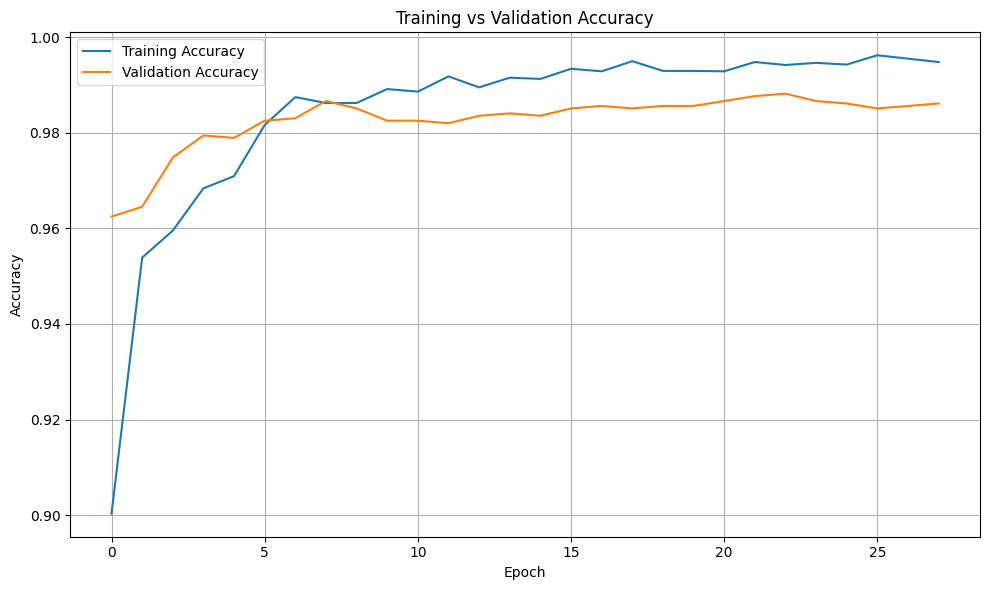

In [29]:
train_accuracy = (
    history.history["accuracy"]
    + fine_tune_history.history["accuracy"]
)

val_accuracy = (
    history.history["val_accuracy"]
    + fine_tune_history.history["val_accuracy"]
)

plt.figure(figsize=(10, 6))

plt.plot(
    train_accuracy,
    label="Training Accuracy"
)

plt.plot(
    val_accuracy,
    label="Validation Accuracy"
)

plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

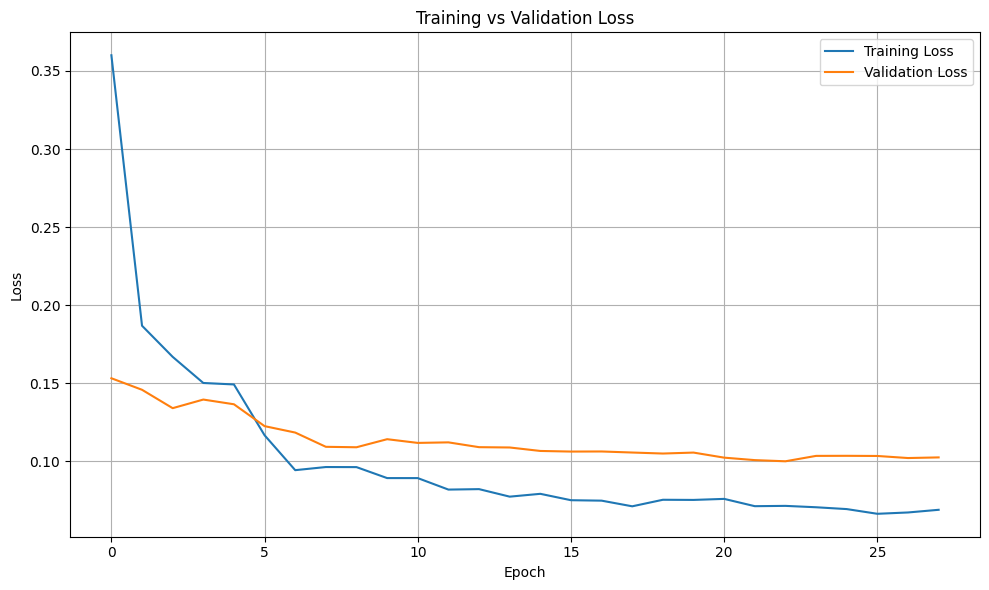

In [30]:
train_loss = (
    history.history["loss"]
    + fine_tune_history.history["loss"]
)

val_loss = (
    history.history["val_loss"]
    + fine_tune_history.history["val_loss"]
)

plt.figure(figsize=(10, 6))

plt.plot(
    train_loss,
    label="Training Loss"
)

plt.plot(
    val_loss,
    label="Validation Loss"
)

plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

In [31]:
y_true = []
y_pred = []

for images, labels in val_ds:

    predictions = best_model.predict(
        images,
        verbose=0
    )

    y_true.extend(
        np.argmax(labels.numpy(), axis=1)
    )

    y_pred.extend(
        np.argmax(predictions, axis=1)
    )

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print(
    classification_report(
        y_true,
        y_pred,
        labels=list(range(len(class_names))),
        target_names=class_names,
        zero_division=0
    )
)

                     precision    recall  f1-score   support

Potato_Early_Blight       0.99      1.00      0.99       201
     Potato_Healthy       0.94      1.00      0.97        31
 Potato_Late_Blight       1.00      0.99      0.99       201
Tomato_Early_Blight       0.98      0.96      0.97       224
     Tomato_Healthy       1.00      1.00      1.00       333
 Tomato_Late_Blight       0.98      0.99      0.98       406
Tomato_Mosaic_Virus       0.99      0.99      0.99       548

           accuracy                           0.99      1944
          macro avg       0.98      0.99      0.98      1944
       weighted avg       0.99      0.99      0.99      1944



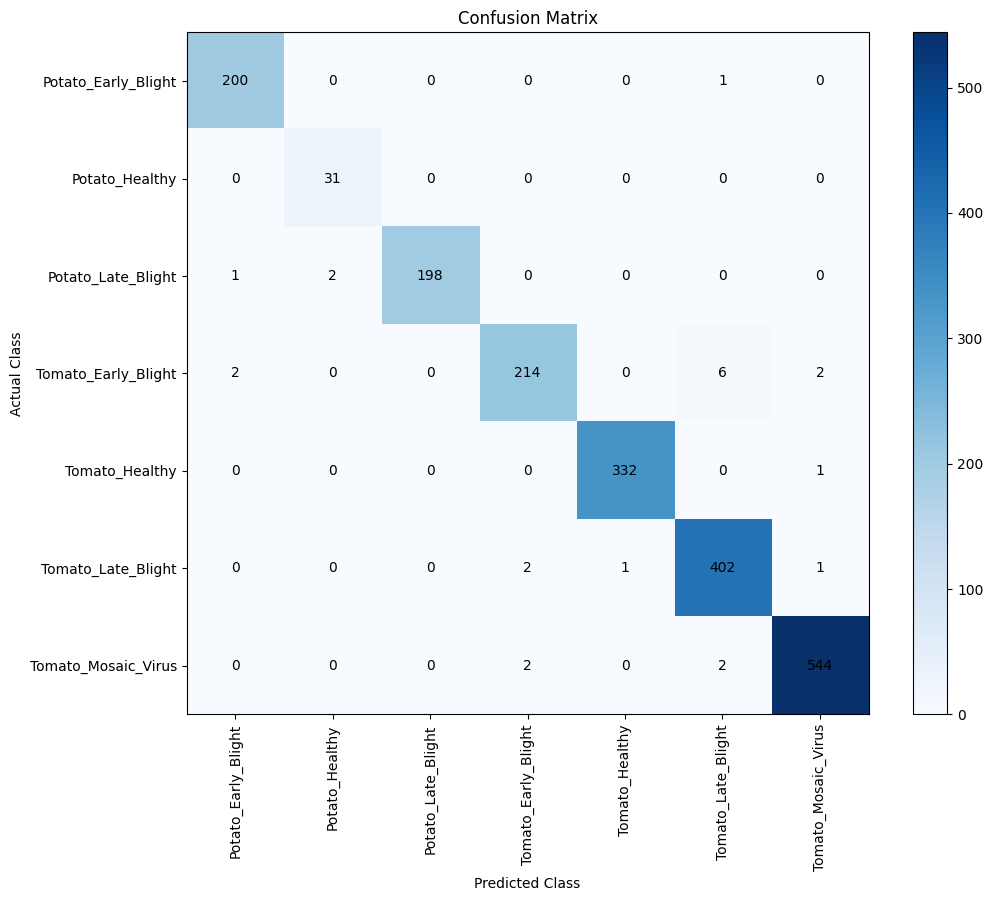

In [32]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(len(class_names))
)

plt.figure(figsize=(11, 9))

plt.imshow(
    cm,
    cmap="Blues"
)

plt.title("Confusion Matrix")
plt.colorbar()

ticks = np.arange(len(class_names))

plt.xticks(
    ticks,
    class_names,
    rotation=90
)

plt.yticks(
    ticks,
    class_names
)

for i in range(len(class_names)):

    for j in range(len(class_names)):

        plt.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center"
        )

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()

Loaded leaf image: sample_leaf_images/potato_early_blight_sample.jpg


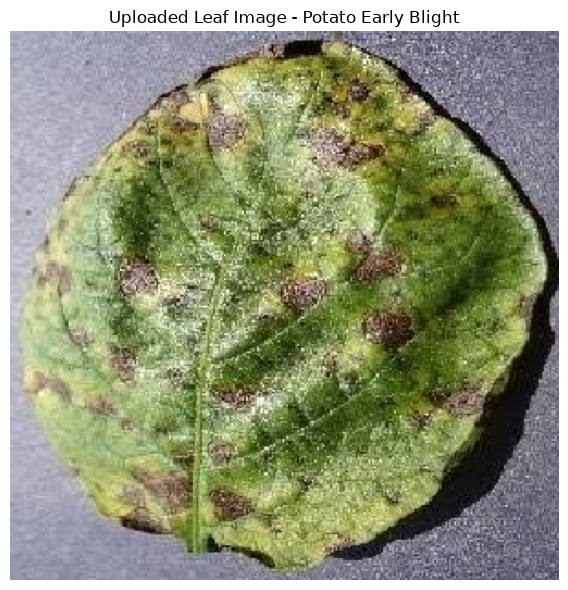

Loaded leaf image: sample_leaf_images/potato_early_blight_sample.jpg
CROP: Potato
PREDICTED CLASS: Potato_Early_Blight
DISEASE / STATUS: Early_Blight
MODEL CONFIDENCE: 100.00%

Class probabilities:
Potato_Early_Blight          : 100.00%
Potato_Healthy               : 0.00%
Potato_Late_Blight           : 0.00%
Tomato_Early_Blight          : 0.00%
Tomato_Healthy               : 0.00%
Tomato_Late_Blight           : 0.00%
Tomato_Mosaic_Virus          : 0.00%


In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras

# Sample leaf image provided for testing
sample_image_path = "sample_leaf_images/potato_early_blight_sample.jpg"
if not os.path.exists(sample_image_path):
    sample_image_path = "potato_early_blight_sample.jpg"

uploaded_file = None
if os.path.exists(sample_image_path):
    uploaded_file = sample_image_path
    print(f"Loaded leaf image: {uploaded_file}")
else:
    try:
        from google.colab import files
        uploaded = files.upload()
        if uploaded:
            uploaded_file = next(iter(uploaded))
    except Exception as e:
        print(f"Upload error: {e}")

if uploaded_file:
    img = keras.utils.load_img(
        uploaded_file,
        target_size=(
            IMAGE_HEIGHT,
            IMAGE_WIDTH
        )
    )

    plt.figure(figsize=(6, 6))
    plt.imshow(img)
    plt.axis("off")
    plt.title("Uploaded Leaf Image")
    plt.show()

    img_array = keras.utils.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)

    # Ensure best_model is available
    if 'best_model' not in globals():
        import tensorflow as tf
        for m_path in ["/content/Best_Tomato_Potato_Model.keras", "Model/Tomato_Potato_Disease_Model.keras"]:
            if os.path.exists(m_path):
                best_model = tf.keras.models.load_model(m_path)
                break

    predictions = best_model.predict(
        img_array,
        verbose=0
    )[0]

    predicted_index = np.argmax(predictions)
    predicted_class = class_names[predicted_index]
    confidence = predictions[predicted_index] * 100

    crop_name, disease_name = predicted_class.split("_", 1)

    print("=" * 50)
    print("CROP:", crop_name)
    print("PREDICTED CLASS:", predicted_class)
    print("DISEASE / STATUS:", disease_name)
    print(f"MODEL CONFIDENCE: {confidence:.2f}%")
    print("=" * 50)

    print("\nClass probabilities:")
    for i, class_name in enumerate(class_names):
        print(
            f"{class_name:28} : "
            f"{predictions[i] * 100:.2f}%"
        )


In [34]:
MODEL_PATH = "/content/Tomato_Potato_Disease_Model.keras"
LABELS_PATH = "/content/Tomato_Potato_Labels.txt"

best_model.save(MODEL_PATH)

with open(LABELS_PATH, "w") as file:

    for class_name in class_names:

        file.write(class_name + "\n")

print("Model saved:", MODEL_PATH)
print("Labels saved:", LABELS_PATH)

Model saved: /content/Tomato_Potato_Disease_Model.keras
Labels saved: /content/Tomato_Potato_Labels.txt


In [35]:
from google.colab import files

files.download(
    "/content/Tomato_Potato_Disease_Model.keras"
)

files.download(
    "/content/Tomato_Potato_Labels.txt"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>